CREDIT SCORE DATASET
   Income   Debt  Payment_History  Credit_Utilization Credit_Score
0   50000  10000               90                  20         Good
1   30000  15000               60                  75         Poor
2   80000  12000               95                  15         Good
3   25000  18000               50                  85         Poor
4   90000   8000               98                  10         Good

ACTUAL CREDIT SCORES:
['Good', 'Good', 'Good', 'Poor', 'Good', 'Poor']

PREDICTED CREDIT SCORES:
['Standard', 'Good', 'Good', 'Poor', 'Good', 'Standard']

Accuracy: 66.67 %

CONFUSION MATRIX:
[[3 0 1]
 [0 1 1]
 [0 0 0]]


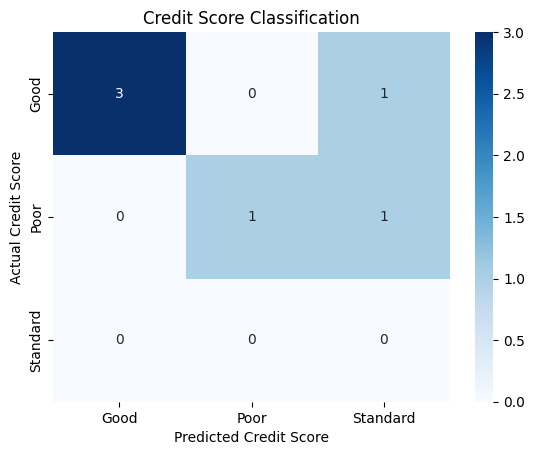


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        Good       1.00      0.75      0.86         4
        Poor       1.00      0.50      0.67         2
    Standard       0.00      0.00      0.00         0

    accuracy                           0.67         6
   macro avg       0.67      0.42      0.51         6
weighted avg       1.00      0.67      0.79         6


NEW CUSTOMER PREDICTION:
Predicted Credit Score: Good

Program executed successfully.


In [12]:

# Credit Score Classification using Decision Tree

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

# Step 1: Create dataset
data = {
    "Income": [50000, 30000, 80000, 25000, 90000,
               45000, 70000, 20000, 85000, 35000,
               60000, 28000, 95000, 40000, 75000,
               55000, 32000, 82000, 27000, 88000],
    "Debt": [10000, 15000, 12000, 18000, 8000,
             20000, 10000, 19000, 9000, 17000,
             11000, 16000, 7000, 14000, 9000,
             12000, 18000, 9500, 20000, 8500],
    "Payment_History": [90, 60, 95, 50, 98,
                        55, 88, 40, 96, 58,
                        85, 52, 99, 65, 92,
                        82, 48, 94, 45, 97],
    "Credit_Utilization": [20, 75, 15, 85, 10,
                           80, 25, 90, 12, 78,
                           30, 82, 8, 70, 18,
                           35, 88, 14, 92, 11],
    "Credit_Score": [
        "Good", "Poor", "Good", "Poor", "Good",
        "Poor", "Good", "Poor", "Good", "Poor",
        "Good", "Poor", "Good", "Standard", "Good",
        "Good", "Poor", "Good", "Poor", "Good"
    ]
}

df = pd.DataFrame(data)

print("CREDIT SCORE DATASET")
print(df.head())

# Step 2: Separate features and target
X = df[["Income", "Debt", "Payment_History",
        "Credit_Utilization"]]
y = df["Credit_Score"]

# Step 3: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Step 4: Create and train the model
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Step 5: Make predictions
y_pred = model.predict(X_test)

print("\nACTUAL CREDIT SCORES:")
print(list(y_test))

print("\nPREDICTED CREDIT SCORES:")
print(list(y_pred))

# Step 6: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", round(accuracy * 100, 2), "%")

# Step 7: Confusion matrix
labels = ["Good", "Poor", "Standard"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

print("\nCONFUSION MATRIX:")
print(cm)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.xlabel("Predicted Credit Score")
plt.ylabel("Actual Credit Score")
plt.title("Credit Score Classification")
plt.show()

# Step 8: Classification report
print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test, y_pred, labels=labels, zero_division=0
))

# Step 9: Predict a new customer
new_customer = pd.DataFrame({
    "Income": [65000],
    "Debt": [10000],
    "Payment_History": [90],
    "Credit_Utilization": [20]
})

prediction = model.predict(new_customer)

print("\nNEW CUSTOMER PREDICTION:")
print("Predicted Credit Score:", prediction[0])

print("\nProgram executed successfully.")
